In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
#Sebastian Torres Rut:21.605.743-0

In [2]:
#configuracion de la semilla
rng = np.random.default_rng(seed=2543)

#Parte 1

#generacion de datos aleatorios para las caracteristicas de las 100 estrellas

radios_solares = rng.uniform(0.5,5,100)

distancias_parsec = rng.uniform(50,500,100)

temperatura_ef_kelvin = rng.uniform(3000,10000,100)

ID_estrellas = list(range(1, 101))
print(temperatura_ef_kelvin)

[8389.74386702 9920.3204555  8094.78218919 9269.83116935 4526.31285559
 5251.70758243 4756.02370842 9100.30419174 4821.85496087 4152.97404496
 9210.9673763  7590.72659112 7162.56556381 8022.32052718 6634.1859934
 8235.59369464 4799.53345597 5866.24884227 7064.66742829 9085.15723585
 7015.0002889  7546.18353488 8848.49590401 4165.07940654 9786.15619445
 8009.70758335 6242.35842475 3192.98969534 9721.65766162 9310.43159146
 9135.8952185  8508.69469418 7603.10490929 4636.80859983 9068.50735803
 7422.17795718 4535.65811924 5792.68094423 7614.71045083 6017.11989818
 9512.11299609 9347.28675539 6245.28505717 3237.29834265 6565.5323844
 7332.51236961 9732.65866027 4278.99462911 4406.45199997 6267.01454716
 5694.28384829 8756.61248647 4037.43897185 5695.02578062 7783.56459518
 3239.14024288 5658.15916301 4893.91814068 4751.96561253 3465.04242152
 3340.99436039 5420.30037989 5696.2757535  4238.67072919 7939.28667261
 3482.56273539 8787.84781637 9503.10670481 9207.1945744  9710.86977202
 8318.82

In [3]:
#Juntamos la informacio0n en un diccionario para que las columnas contengan un nombre.
dic_1 = {'ID':ID_estrellas,'Radio estelar (R⊙)':radios_solares,'Distancia (pc)':distancias_parsec,'Temperatura efectiva (K)':temperatura_ef_kelvin}


#Creacion del dataframe

data_frame_1 = pd.DataFrame(dic_1)
data_frame_1.head(10)
data_frame_1.describe()

,ID,Radio estelar (R⊙),Distancia (pc),Temperatura efectiva (K)
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,2.718477,279.777227,6765.371150
std,29.011492,1.317261,124.682630,1994.417893
min,1.000000,0.522263,53.082832,3030.693741
25%,25.750000,1.652232,182.019746,4920.890110
50%,50.500000,2.689403,275.500532,6655.250630
75%,75.250000,3.743176,394.497177,8419.481574
max,100.000000,4.984588,490.755783,9965.530641


In [4]:
#Parte 2
#Importaremos sigma de la libreria scipy para utilizar la constante de Stefan-Boltzmann (esta cte se encuentra en el S.I.)
from scipy.constants import sigma
print(sigma)
#creamos dos funciones que describan la ecuacion de la luminosidad de una estrella y la de su flujo

def calculo_luminosidad(radio,temp):
    ecu = 4*np.pi*(radio**2)*sigma*(temp**4)
    return ecu

def calculo_flujo(radio1,temp1,distancia1):
    ecuacion = calculo_luminosidad(radio1,temp1)*((4*np.pi*(distancia1**2))**(-1))
    return ecuacion

5.6703744191844314e-08


In [5]:
#para realizzar la seccion a) debemos transformar el dataframe a unidades internacionales
#y posteriormente trasparasar el resultado a las unidades deseadas

#clonaremos el dataframe para pasar la copia a S.I.

si_dataframe = data_frame_1.copy()

#La conversion de unidades para la columna de radio solares es 1 radio solar = 6.957 × 10^8 metros.

si_dataframe['Radio estelar (R⊙)'] = si_dataframe['Radio estelar (R⊙)']* 6.957*(10**8)

#Reescribiremos el nombre del a columna para cambiar sus unidades
si_dataframe.rename(columns={'Radio estelar (R⊙)': 'Radio estelar (m)'}, inplace=True)

#Conversion de parsec a metro (1 parsec ≈ 3.086 × 10^16 metros).
si_dataframe['Distancia (pc)'] = si_dataframe['Distancia (pc)']*3.086*(10**16)
#Cambio de nombre
si_dataframe.rename(columns={'Distancia (pc)': 'Distancia (m)'}, inplace=True)
si_dataframe

,ID,Radio estelar (m),Distancia (m),Temperatura efectiva (K)
0,1,2.733961e+09,2.237946e+18,8389.743867
1,2,3.443615e+09,7.178909e+18,9920.320455
2,3,2.667503e+09,4.258232e+18,8094.782189
3,4,3.409463e+09,1.246293e+19,9269.831169
4,5,2.475194e+09,4.886971e+18,4526.312856
...,...,...,...,...
95,96,2.440423e+09,1.048811e+19,9259.685422
96,97,6.900922e+08,6.239868e+18,8580.669270
97,98,7.356328e+08,9.519008e+18,8250.739056
98,99,4.614327e+08,1.408314e+19,6627.461526


In [6]:
#Extraeremos las columnas y mediante un ciclo for crearemos un array con el calculo de la luminosidad
Id_test = si_dataframe['ID'].values
si_dist = si_dataframe['Distancia (m)'].values
si_radio = si_dataframe['Radio estelar (m)'].values
si_temp = si_dataframe['Temperatura efectiva (K)'].values

#creacion de un array vacio para el resultado de la luminosidad
si_luminosidad = np.zeros(100)
for i in Id_test:
    valor = calculo_luminosidad(si_radio[i-1],si_temp[i-1])
    si_luminosidad[i-1] = valor
print(si_luminosidad)

[2.63876606e+28 8.18377492e+28 2.17696765e+28 6.11619005e+28
 1.83239244e+27 5.99593535e+27 2.84709291e+27 1.06044130e+28
 1.72747783e+26 2.05825651e+27 1.85429490e+28 9.98636504e+27
 1.41573085e+28 1.12874910e+28 3.05231442e+27 1.64146602e+27
 1.64692876e+26 3.06107109e+26 8.87539946e+27 1.16730377e+28
 1.16526153e+28 9.20612305e+26 5.25293333e+28 1.55867835e+26
 9.50945764e+27 2.86216270e+28 3.44530917e+27 9.41025962e+25
 3.00585270e+28 2.17408991e+28 3.31618849e+28 7.32131146e+27
 9.44460750e+26 1.36758940e+27 3.50439603e+28 6.77879119e+27
 4.24073684e+25 1.40891109e+26 1.59428808e+28 1.71165730e+27
 1.20363804e+28 5.44253673e+28 8.05159011e+27 5.81065743e+26
 8.66543091e+27 3.78070588e+27 8.93509313e+26 2.80527678e+27
 1.84492681e+27 5.61015039e+27 1.50543525e+27 4.13194662e+28
 6.16976919e+25 6.36959989e+27 5.98652660e+26 1.61835289e+26
 1.15906216e+27 6.26405866e+26 3.41773236e+27 9.42133121e+25
 1.10626646e+26 1.45774672e+27 4.84800622e+27 3.38756970e+25
 2.36263020e+27 5.864431

In [7]:
#finalmente transformaremos el array generado a luminosidades solares (dividiremos por 3,828 × 10²⁶ W).
luminosidad_solar = si_luminosidad * (3.828*(10**26)**(-1))
print(luminosidad_solar)

[1.01011965e+03 3.13274904e+03 8.33343216e+02 2.34127755e+03
 7.01439827e+01 2.29524405e+02 1.08986716e+02 4.05936931e+02
 6.61278512e+00 7.87900593e+01 7.09824088e+02 3.82278054e+02
 5.41941770e+02 4.32085156e+02 1.16842596e+02 6.28353192e+01
 6.30444328e+00 1.17177801e+01 3.39750291e+02 4.46843882e+02
 4.46062114e+02 3.52410390e+01 2.01082288e+03 5.96662073e+00
 3.64022039e+02 1.09563588e+03 1.31886435e+02 3.60224738e+00
 1.15064041e+03 8.32241619e+02 1.26943695e+03 2.80259803e+02
 3.61539575e+01 5.23513224e+01 1.34148280e+03 2.59492127e+02
 1.62335406e+00 5.39331164e+00 6.10293476e+02 6.55222414e+01
 4.60752642e+02 2.08340306e+03 3.08214869e+02 2.22431967e+01
 3.31712695e+02 1.44725421e+02 3.42035365e+01 1.07385995e+02
 7.06237982e+01 2.14756557e+02 5.76280614e+01 1.58170917e+03
 2.36178765e+00 2.43828284e+02 2.29164238e+01 6.19505487e+00
 4.43688995e+01 2.39788166e+01 1.30830795e+02 3.60648559e+00
 4.23478800e+00 5.58025444e+01 1.85581678e+02 1.29676168e+00
 9.04414842e+01 2.244904

In [8]:
#para cocmpletar la seccion b) solo debemos utilizar la informacion ya utilizada, ya que el enunciado nos pide unidades S.I.
si_flujo = np.zeros(100)
for j in Id_test:
    coso = calculo_flujo(si_radio[j-1],si_temp[j-1],si_dist[j-1])
    si_flujo[j-1]= coso
print(si_flujo)

[4.19268195e-10 1.26365039e-10 9.55396133e-11 3.13350641e-11
 6.10561027e-12 5.74632015e-12 1.02695637e-11 2.58402463e-11
 6.85808968e-14 1.11437333e-12 2.95351058e-10 2.67202262e-10
 2.89086353e-11 1.79926376e-10 1.67150842e-11 7.46335021e-12
 4.15344545e-13 5.11635606e-13 2.39009263e-11 8.63279388e-12
 5.62657018e-12 3.34017394e-12 2.59452392e-11 1.12552745e-13
 3.78965011e-11 5.16525832e-10 2.81139269e-12 2.18439673e-13
 2.11501143e-11 8.33843903e-12 1.56009964e-11 2.74463535e-12
 1.93455644e-12 1.11025673e-12 1.38671369e-10 4.87726047e-12
 7.94061148e-14 6.02421863e-14 5.77952241e-12 3.45336012e-12
 1.38649316e-11 4.64795494e-11 4.46689570e-11 6.99622894e-13
 7.00624694e-12 1.55897501e-12 4.74145027e-13 2.67050881e-12
 8.06758802e-13 8.69115800e-11 1.78507201e-12 1.93275024e-11
 1.04135154e-13 2.63300010e-12 5.29325569e-13 1.80826517e-13
 9.47000765e-13 3.76605125e-13 5.43521561e-12 3.98017443e-14
 8.20480287e-14 7.76625909e-13 7.61502129e-12 2.82264056e-14
 9.85733899e-13 1.295433

In [9]:
#Para completar la seccion c) ingresaremos nuestros arrays a una copiu del dataframe original.
data_fra = data_frame_1.copy()
data_fra['Luminosidad (L⊙)'] = luminosidad_solar
data_fra['Flujo observado (W/m^2)'] = si_flujo
data_fra.head(10)

,ID,Radio estelar (R⊙),Distancia (pc),Temperatura efectiva (K),Luminosidad (L⊙),Flujo observado (W/m^2)
0,1,3.929798,72.519305,8389.743867,1010.119646,4.192682e-10
1,2,4.949857,232.628284,9920.320455,3132.749040,1.263650e-10
2,3,3.834271,137.985482,8094.782189,833.343216,9.553961e-11
3,4,4.900767,403.853953,9269.831169,2341.277550,3.133506e-11
4,5,3.557847,158.359402,4526.312856,70.143983,6.105610e-12
5,6,4.780734,295.279099,5251.707582,229.524405,5.746320e-12
6,7,4.016798,152.203265,4756.023708,108.986716,1.026956e-11
7,8,2.117379,185.180025,9100.304192,405.936931,2.584025e-11
8,9,0.962598,458.779292,4821.854961,6.612785,6.858090e-14
9,10,4.479180,392.856136,4152.974045,78.790059,1.114373e-12


In [10]:
#utilizaremos las funciones idmax y idmin de pandas para responder a la seccion d).
max_lum = data_fra['Luminosidad (L⊙)'].idxmax()
min_lum = data_fra['Luminosidad (L⊙)'].idxmin()

max_flujo = data_fra['Flujo observado (W/m^2)'].idxmax()
min_flujo = data_fra['Flujo observado (W/m^2)'].idxmin()

print('Estrella con mayor luminosidad')
print(data_fra.loc[max_lum, ['ID', 'Luminosidad (L⊙)']])

print('Estrella de menor luminosidad')
print(data_fra.loc[min_lum, ['ID', 'Luminosidad (L⊙)']])

print('Estrella de mayor flujo')
print(data_fra.loc[max_flujo, ['ID', 'Flujo observado (W/m^2)']])

print('Estrella de menor flujo')
print(data_fra.loc[min_flujo, ['ID', 'Flujo observado (W/m^2)']])

Estrella con mayor luminosidad
ID                     2.00000
Luminosidad (L⊙)    3132.74904
Name: 1, dtype: float64
Estrella de menor luminosidad
ID                  64.000000
Luminosidad (L⊙)     1.296762
Name: 63, dtype: float64
Estrella de mayor flujo
ID                         2.600000e+01
Flujo observado (W/m^2)    5.165258e-10
Name: 25, dtype: float64
Estrella de menor flujo
ID                         6.400000e+01
Flujo observado (W/m^2)    2.822641e-14
Name: 63, dtype: float64


In [11]:
#Parte 3
#pimro gneraremos una mascara que nos permitira separar aquellas estrellas que son detectadas y las que no lo son.
detectadas = (data_fra['Flujo observado (W/m^2)'] >= 2*(10**(-10)))
#Para obtener las no detectadas utilizaemos el complmento de la mascara anterior.
no_detectadas = ~detectadas

#a) Utilizando el mismo metodo anterior creearemos una nueva columna con la mascara creada.
data_fra['Clasificacion'] = detectadas
data_fra

,ID,Radio estelar (R⊙),Distancia (pc),Temperatura efectiva (K),Luminosidad (L⊙),Flujo observado (W/m^2),Clasificacion
0,1,3.929798,72.519305,8389.743867,1010.119646,4.192682e-10,True
1,2,4.949857,232.628284,9920.320455,3132.749040,1.263650e-10,False
2,3,3.834271,137.985482,8094.782189,833.343216,9.553961e-11,False
3,4,4.900767,403.853953,9269.831169,2341.277550,3.133506e-11,False
4,5,3.557847,158.359402,4526.312856,70.143983,6.105610e-12,False
...,...,...,...,...,...,...,...
95,96,3.507866,339.860939,9259.685422,1194.286600,2.257004e-11,False
96,97,0.991939,202.199206,8580.669270,70.419406,3.759757e-12,False
97,98,1.057399,308.457802,8250.739056,68.404882,1.569358e-12,False
98,99,0.663264,456.355933,6627.461526,11.204673,1.174406e-13,False


In [12]:
#b) para completar eesta pregunta utilizaremos lafuncion valuecounts y sum para  sumar todas las instancias de true para la pregunta posterior

cantidad_true = data_fra['Clasificacion'].sum()
print(cantidad_true)
data_fra['Clasificacion'].value_counts()

4


Clasificacion
False    96
True      4
Name: count, dtype: int64

In [13]:
#c) para calcular el % de estrellas detectadas utilizaremos la siguiente funcion para calcularlo, en donde true_contador es la cantidad de valores
#true del dataframe y total es la cantidad de estrellas totales
def porcentaje(true_contador,total):
    calculo = 100*true_contador*(total**(-1))
    return calculo

print(f'El porcentaje de estrellas detectadas es de : {porcentaje(cantidad_true,100)}%')

El porcentaje de estrellas detectadas es de : 4.0%


In [14]:
#d utilizando la mascara generada para ambos grupos de estrellas podemos extraer en dos array ambos grupos y calccular sus respectivos promedios

dataa = ['Flujo observado (W/m^2)', 'Distancia (pc)', 'Temperatura efectiva (K)']
print('Estrellas detectadas')
promedios_detectadas = data_fra[detectadas][dataa].mean()
print(promedios_detectadas)

print('Estrellas no detectadas')
promedios_no_detectadas = data_fra[no_detectadas][dataa].mean()
print(promedios_no_detectadas)

Estrellas detectadas
Flujo observado (W/m^2)     3.745868e-10
Distancia (pc)              6.721962e+01
Temperatura efectiva (K)    8.300286e+03
dtype: float64
Estrellas no detectadas
Flujo observado (W/m^2)     1.872142e-11
Distancia (pc)              2.886338e+02
Temperatura efectiva (K)    6.701416e+03
dtype: float64


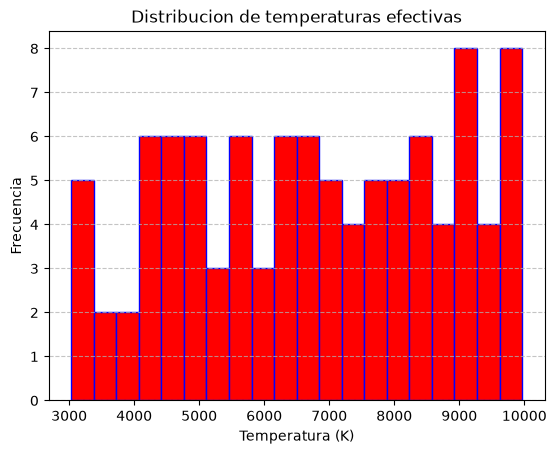

In [15]:
#Parte 4
#a)
plt.hist(data_fra['Temperatura efectiva (K)'],bins=20,color='r',edgecolor='b')
plt.title('Distribucion de temperaturas efectivas')
plt.xlabel('Temperatura (K)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75, linestyle='--')
plt.show()

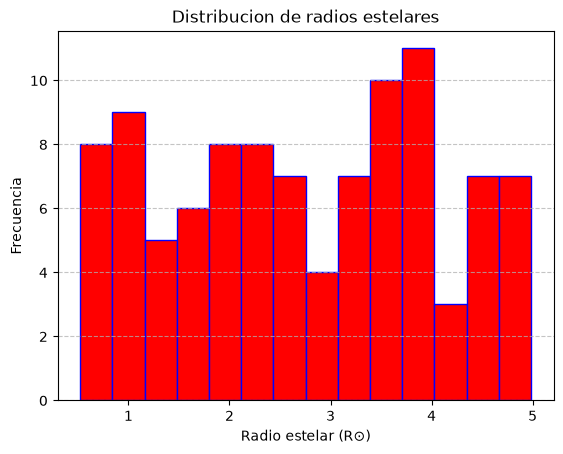

In [16]:
#b)
plt.hist(data_fra['Radio estelar (R⊙)'],bins=14,color='r',edgecolor='b')
plt.title('Distribucion de radios estelares')
plt.xlabel('Radio estelar (R⊙)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75, linestyle='--')
plt.show()

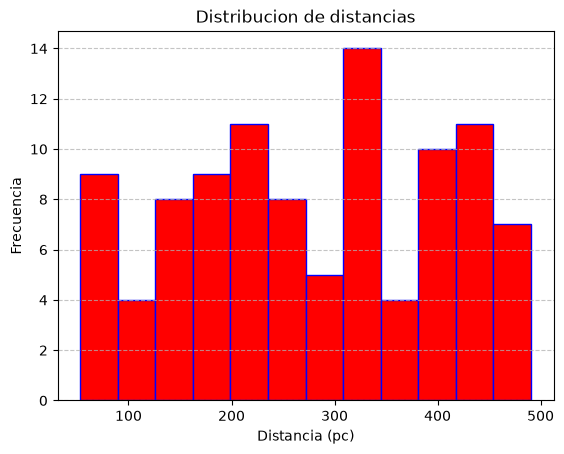

In [17]:
#c)
plt.hist(data_fra['Distancia (pc)'],bins=12,color='r',edgecolor='b')
plt.title('Distribucion de distancias')
plt.xlabel('Distancia (pc)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75, linestyle='--')
plt.show()

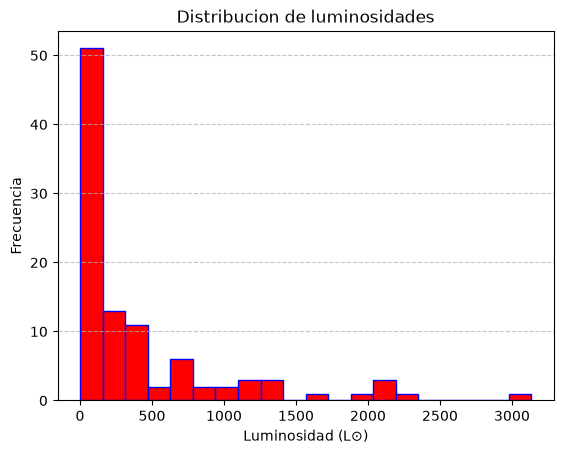

In [18]:
#d)
plt.hist(data_fra['Luminosidad (L⊙)'],bins=20,color='r',edgecolor='b')
plt.title('Distribucion de luminosidades')
plt.xlabel('Luminosidad (L⊙)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75, linestyle='--')
plt.show()

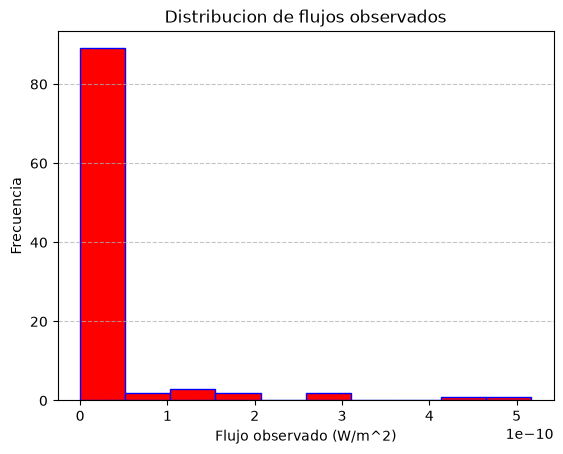

In [19]:
#e)
plt.hist(data_fra['Flujo observado (W/m^2)'],bins=10,color='r',edgecolor='b')
plt.title('Distribucion de flujos observados')
plt.xlabel('Flujo observado (W/m^2)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75, linestyle='--')
plt.show()

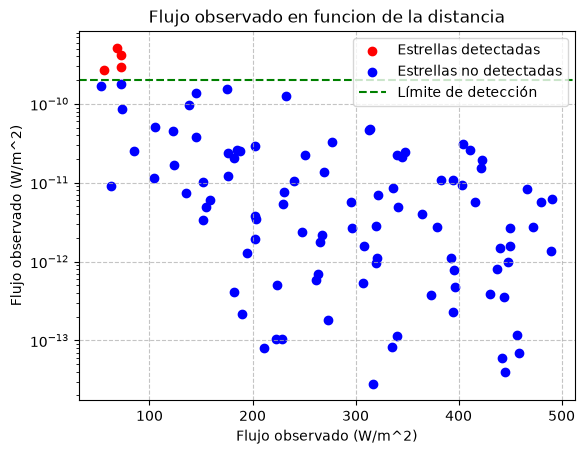

In [20]:
#f)
#ploteamoos ambos grupos de estrellas separados por la mascara generada anteriormente
plt.scatter(data_fra[detectadas]['Distancia (pc)'],data_fra[detectadas]['Flujo observado (W/m^2)'],color='r',label='Estrellas detectadas')
plt.scatter(data_fra[no_detectadas]['Distancia (pc)'],data_fra[no_detectadas]['Flujo observado (W/m^2)'],color='b',label='Estrellas no detectadas')
#agregamos una escala logaritmita en el eje y para una mejor visualizacion de los datos a grandes distancias
plt.yscale('log')
#titulos y fondo
plt.title('Flujo observado en funcion de la distancia')
plt.xlabel('Flujo observado (W/m^2)')
plt.ylabel('Flujo observado (W/m^2)')
plt.grid(alpha=0.75, linestyle='--')
#linea que las separa
plt.axhline(y=2e-10, color='g', linestyle='--', label='Límite de detección')
plt.legend()
plt.show()

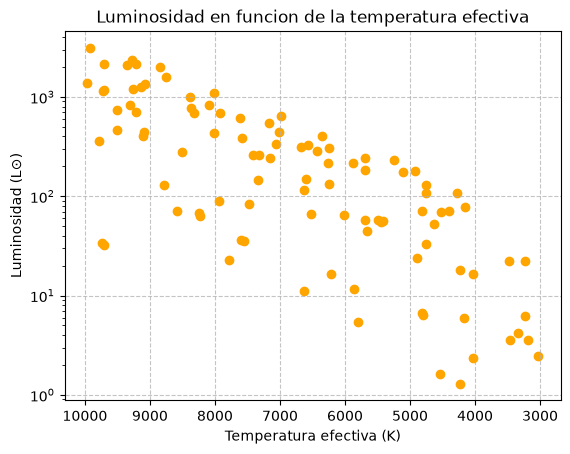

In [23]:
#g)
#ploteamoos con los datos ordenados
plt.scatter(data_fra['Temperatura efectiva (K)'], data_fra['Luminosidad (L⊙)'], color='orange')
#agregamos una escala logaritmita en el eje y 
plt.yscale('log')
#invertimos los valores del eje x
plt.gca().invert_xaxis()
#titulos y fondo
plt.title('Luminosidad en funcion de la temperatura efectiva')
plt.xlabel('Temperatura efectiva (K)')
plt.ylabel('Luminosidad (L⊙)')
plt.grid(alpha=0.75, linestyle='--')
plt.show()